# UTA Softball DATA 4380 Project

#### Group Members: Michael Sheehey, Nathan Butler, Franklin Osualaaham, Sarthakkumar Patel, Joseph Uzoigwe

### Research Questions:
#### 1. Which pitch characteristics are associated with successful pitching outcomes?
#### 4. Can we identify different pitching styles based on velocity, spin rate, and ball movement?

In [37]:
%pip install missingno
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import missingno as msno
from matplotlib.colors import ListedColormap

# Locate the CSV file
csv_path = Path("South Dakota State_0466 (1).csv")

# read into pandas datafrrame
df = pd.read_csv(csv_path)

# check load with dimensions and head
print("Dataset shape (rows, cols):", df.shape)
print(df.head())

Note: you may need to restart the kernel to use updated packages.
Dataset shape (rows, cols): (259, 125)
   PitchNo       Date        Time  PAofInning  PitchofPA        Pitcher  \
0      1.0  3/14/2026  3:33:43 PM         1.0        1.0  Kynlee Bowlin   
1      2.0  3/14/2026  3:33:59 PM         1.0        2.0  Kynlee Bowlin   
2      3.0  3/14/2026  3:34:33 PM         1.0        3.0  Kynlee Bowlin   
3      4.0  3/14/2026  3:35:00 PM         2.0        1.0  Kynlee Bowlin   
4      5.0  3/14/2026  3:35:20 PM         2.0        2.0  Kynlee Bowlin   

  PitcherId PitcherThrows  PitcherTeam          Batter  ...  \
0       NaN         Right  Uta fall 25     Bria Riebel  ...   
1       NaN         Right  Uta fall 25     Bria Riebel  ...   
2       NaN         Right  Uta fall 25     Bria Riebel  ...   
3       NaN         Right  Uta fall 25  Akayla Barnard  ...   
4       NaN         Right  Uta fall 25  Akayla Barnard  ...   

  yt_EffectiveBattingSpeed yt_ReleaseAccuracy yt_ZoneAccuracy  yt

#### We can already see we are going to have missing values to deal with and we also see our dataset has a size of 259 rows by 125 columns. We may have to reduce our independent variables going forward.

### We need to separate the observations belonging to UTA vs South Dakota State

In [38]:
# count pitches recorded for each pitching team
team_counts = df["PitcherTeam"].value_counts(dropna=False)

display(team_counts)

PitcherTeam
South dakota state [sou03:2025]    131
Uta fall 25                        128
Name: count, dtype: int64

#### Here we isolate the "PitcherTeam" categorical var which gives us a pandas series and then call the value_counts() method to count how frequently each distinct value shows up (by specifying dropna=False were asking pandas to count our missing team labels as well). Here however, because our counts add to 259 we know that there are no missing labels.

### Lets isolate UTA pitchers

In [39]:
# create a separate df containing only pitches thrown by UTA
uta_df = df.loc[df["PitcherTeam"] == "Uta fall 25"].copy()

# verify dimensions
print("UTA dataset shape:", uta_df.shape)

# ID UTA pitchers and count their pitches, include na vals similar to above cell
pitcher_counts = uta_df["Pitcher"].value_counts(dropna=False)

display(pitcher_counts)

UTA dataset shape: (128, 125)


Pitcher
Maddie Furniss    82
Kynlee Bowlin     46
Name: count, dtype: int64

#### Here we ask pandas to check if each val for PitcherTeam matches Uta fall 25. We then keep every row returning true for that match and copy into uta_df as its own separate dataframe without modifying the original.

#### What we've learned so far is that for UTA we are examining two different pitchers from fall of '25. Maddie Furniss has more recorded pitches compared to Kynlee Bowlin which could create some imbalance issues for us in the future if we want to compare performance. The 128 pitches do not represent different athletes here they represent the two same pitchers all from one game. 

### Lets investigate variable types to understand our dataset better

In [40]:
# We want to analyze types for our variables because it will help us determine
# which statistical tests are appropriate

# count how many cols belong to each data type
dtype_counts = uta_df.dtypes.value_counts()

display(dtype_counts)

# create a table that shows every col and its data type
column_types = pd.DataFrame({
    "Column": uta_df.columns,
    "Data Type": uta_df.dtypes.values
})

display(column_types)

float64    94
str        27
int64       4
Name: count, dtype: int64

,Column,Data Type
0,PitchNo,float64
1,Date,str
2,Time,str
3,PAofInning,float64
4,PitchofPA,float64
...,...,...
120,yt_ReleaseDistance,float64
121,Catcher,str
122,CatcherId,str
123,CatcherTeam,str


#### We can see some oddities like PitchNo stored as a float when they are normally ints. Interestingly this can happen when a numeric column contains missing values because traditional NumPy integer arrays cannot represent NaN (will need to investigate further). We also can see date and time are strings, we may want to convert these to datetime objects. 

### Understanding Missing Data

#### Begin with observed-data analysis. We can evaluate imputation later when we understand patterns and have a justified statistical objective.

In [41]:
# again total UTA pitching observations
n = len(uta_df)

# count missing measurments for each var
missing_count = uta_df.isna().sum()

# count observed measuremnets for each var
observed_count = uta_df.notna().sum()

# calc percent of missing measurements
missing_percent = uta_df.isna().mean() * 100

# Show results in summary df
missing_summary = pd.DataFrame({
    "Observed Count": observed_count,
    "Missing Count": missing_count,
    "Missing Percent": missing_percent
})

# sort by percentage
missing_summary = missing_summary.sort_values(
    by="Missing Percent",
    ascending=False
)

print(f"UTA pitching observations: {n}")

# show 25 vars with most missing data
display(missing_summary.head(50).round(2))

UTA pitching observations: 128


,Observed Count,Missing Count,Missing Percent
PitcherId,0,128,100.00
AutoPitchType,0,128,100.00
Notes,0,128,100.00
PitcherSet,0,128,100.00
LastTrackedDistance,0,128,100.00
yt_SeamLat,0,128,100.00
yt_SeamLong,0,128,100.00
Note,0,128,100.00
CatcherId,0,128,100.00
yt_FSRI,0,128,100.00


#### Sorting in descending order places our most incomplete vars first which will help us spot our problems. We can see groupings of missingness, lets see if that implys the same missing values.

In [42]:
# compare two measurements with equal missing counts
features = ["HitSpinRate", "PositionAt110X"]

# a true indication means the measurement is present
availability = uta_df[features].notna()

# compare which pitches have each measurement
overlap_table = pd.crosstab(
    availability["HitSpinRate"],
    availability["PositionAt110X"]
)

display(overlap_table)

PositionAt110X,False,True
HitSpinRate,,
False,101,4
True,4,19


#### We have 23 observations for each var but they only cross at 19 pitches, we would be unable to pair these two.


### Next we will visualize missing data

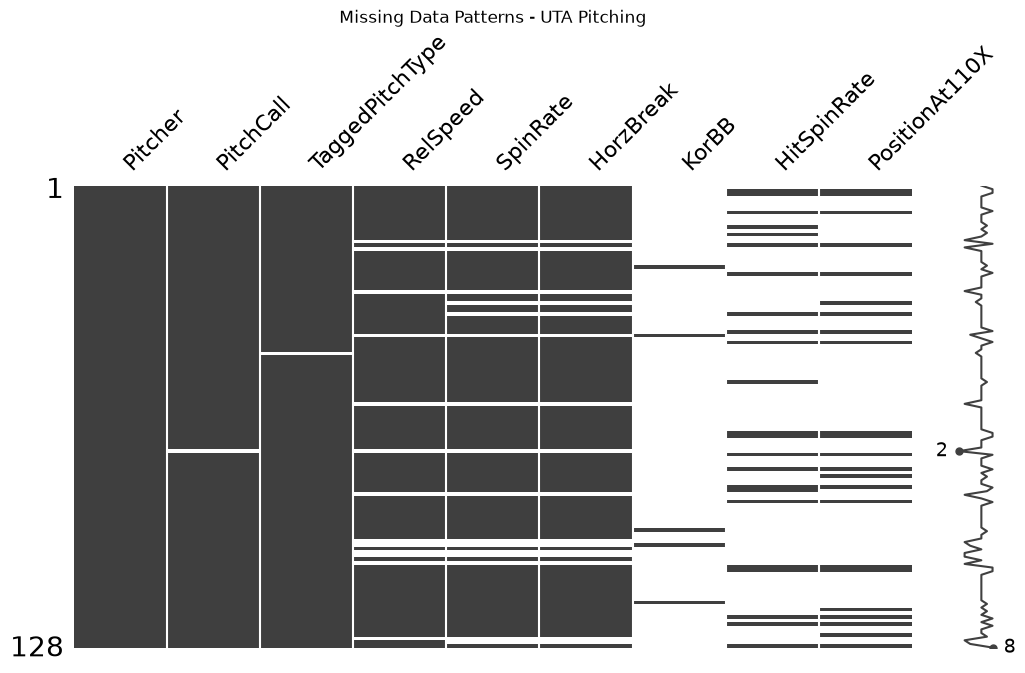

In [43]:
# The selected vars were chosen because at first glance they appear relevent to our research questions
# These vars may be modified in the future

selected_cols = [
    "Pitcher",
    "PitchCall",
    "TaggedPitchType",
    "RelSpeed",
    "SpinRate",
    "HorzBreak",
    "KorBB",
    "HitSpinRate",
    "PositionAt110X"
]

# create a df for missing visuals
missing_df = uta_df[selected_cols].copy()

# ccreate missingness matrix
msno.matrix(missing_df, figsize=(12,6))
plt.title("Missing Data Patterns - UTA Pitching")

plt.show()

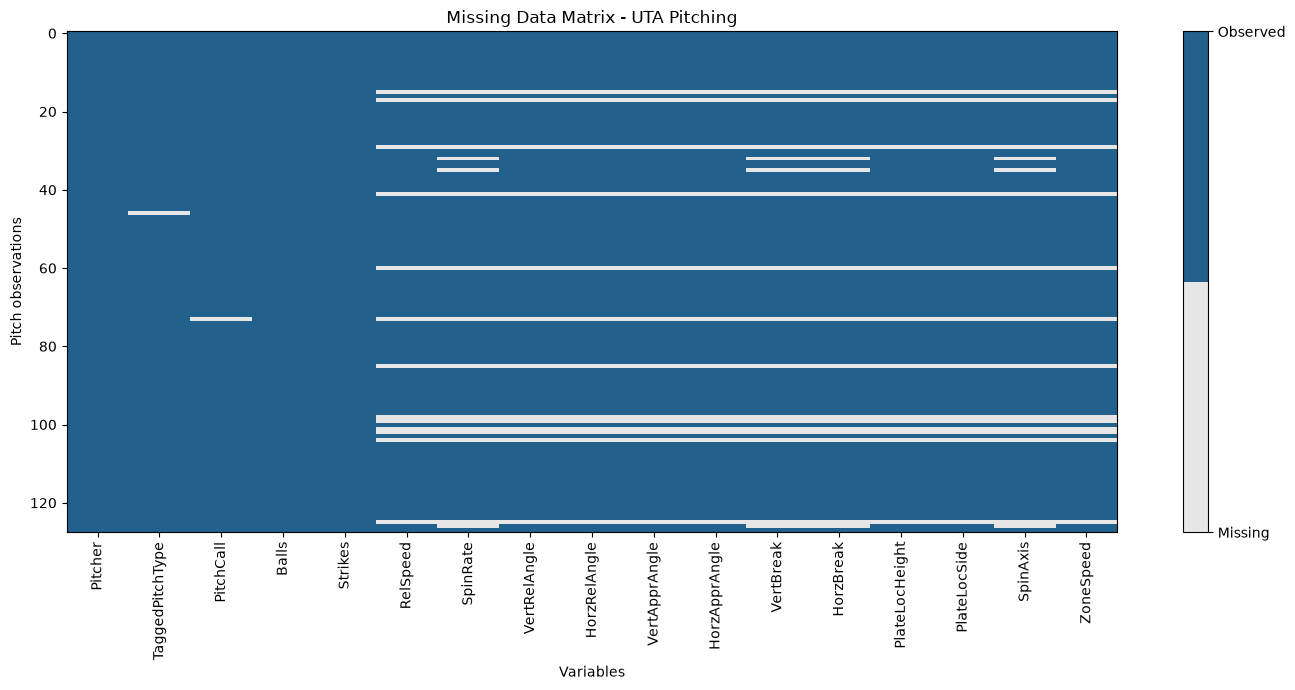

In [44]:
candidate_features = [
    "RelSpeed", "SpinRate",
    "VertRelAngle", "HorzRelAngle",
    "VertApprAngle", "HorzApprAngle",
    "VertBreak", "HorzBreak",
    "PlateLocHeight", "PlateLocSide",
    "SpinAxis", "ZoneSpeed"
]

# contextual vars needed for research questions
context_features = [
    "Pitcher",
    "TaggedPitchType",
    "PitchCall",
    "Balls",
    "Strikes"
]

# Select cols without changing the original dataset
selected_features = context_features + candidate_features
analysis_df = uta_df[selected_features].copy()

# convert each cell into a binary availability indicator
#1 = observed, 0 = missing
availability = analysis_df.notna().astype(int)

# define colors for missing and observed values
colors = ListedColormap(["#E6E6E6", "#21618C"])

fig, ax = plt.subplots(figsize=(14,7))

image = ax.imshow(
    availability.to_numpy(),
    aspect="auto",
    interpolation="nearest",
    cmap=colors,
    vmin=0,
    vmax=1
)

ax.set_xticks(range(len(selected_features)))
ax.set_xticklabels(selected_features, rotation=90)

ax.set_xlabel("Variables")
ax.set_ylabel("Pitch observations")
ax.set_title("Missing Data Matrix - UTA Pitching")

# Add a legend 
colorbar = fig.colorbar(image, ax=ax, ticks=[0,1])
colorbar.ax.set_yticklabels(["Missing", "Observed"])

plt.tight_layout()
plt.show()

#### Our missingness matrix is designed so that each pitch is it's own individual event with each displayed feature. Our data is converted into binary values where 1 means there was a value observed for that feature for that certain pitch while 0 means the value was not observed. We can then construct our missingness matrix.

#### Our contextual variables are nearly complete with only a few events missing and pitcher, balls, and strikes appear fully complete. 

#### We also observe that there is a presence of horizontal white bands aross many of the 12 physical measurements. This suggests the missing values share a common cause. Maybe the tracking equipment failed for these pitches or maybe these records represent a particular event type with incomplete tracking info. 

#### The reason we dont likely have any equipment failure is further observing event columns like spin rate, vert break, horzbreak and spin axis we can see similar bands but in a different pattern

#### need to check, does missing spinrate id all 16 pitches with incomplete physical measurements? as well as are the incomplete measurements distributed evenly between our two pitchers?



In [45]:
# Investigate missingness across pitches and pitchers 

# id whether eachpitch is missing ANY physical feature
analysis_df["missing_physical"] = (
    analysis_df[candidate_features].isna().any(axis=1)
)

# id pitches missing spin rate
analysis_df["missing_spin"] = analysis_df["SpinRate"].isna()

# Count incomplete observations
print(
    "Pitches missing at least one physical feature:",
    analysis_df["missing_physical"].sum()
)

# Determine whether any incomplete pitches have recorded spin
missing_other = (
    analysis_df["missing_physical"]
    & ~analysis_df["missing_spin"]
)

print(
    "Incomplete pitches with recorded SpinRate:",
    missing_other.sum()
)

# summarize missingness by pitcher
pitcher_missing = (
    analysis_df.groupby("Pitcher")["missing_physical"]
    .agg(
        total_pitches="size",
        incomplete_pitches="sum",
        missing_rate="mean"
    )
)

# convert the missing rate into a percentage
pitcher_missing["missing_pct"] = (
    pitcher_missing["missing_rate"] * 100
)

display(
    pitcher_missing[
        ["total_pitches", "incomplete_pitches", "missing_pct"]
        ].round(2)
)



Pitches missing at least one physical feature: 16
Incomplete pitches with recorded SpinRate: 0


,total_pitches,incomplete_pitches,missing_pct
Pitcher,,,
Kynlee Bowlin,46,6,13.04
Maddie Furniss,82,10,12.20


#### Our misingness is almost identical between pitchers, we can also see that SpinRate identifies every incomplete physical record therefor, pitches missing spinrate = pitches missing any of our 12 features. A pitch is incomplete if and only if its spinrate is missing. However, just because spinrate is missing doesnt mean other valuable information is also missing, a pitch without spinrate may still yield valuable info like pitchcall, balls, and strikes. 

In [46]:
# investigate missingness by pitch outcome

# create a grouping variable without modifying PitchCall
pitch_outcome = analysis_df["PitchCall"].fillna("Missing/Unknown")

# create a contingency table
outcome_missing = pd.crosstab(
        pitch_outcome,
        analysis_df["missing_physical"]
    )

# give the output cols names
outcome_missing = outcome_missing.reindex(
    columns=[False, True],
    fill_value=0
)

outcome_missing.columns = ["Complete", "Incomplete"]

# calculate total pitches per outcome
outcome_missing["Total"] = outcome_missing.sum(axis=1)

# calculate percentage of incomplete observations
outcome_missing["Missing %"] = (
    outcome_missing["Incomplete"]
    / outcome_missing["Total"]
    * 100
)

display(outcome_missing.round(2))

,Complete,Incomplete,Total,Missing %
PitchCall,,,,
BallCalled,36,6,42,14.29
Foul,31,5,36,13.89
InPlay,25,4,29,13.79
Missing/Unknown,0,1,1,100.00
StrikeCalled,16,0,16,0.00
StrikeSwinging,4,0,4,0.00


#### each value in our table represents a frequency: the number of observations belonging to a particular combo of categories. Our table shows some interesting results, one being that three pitch outcomes have similar missingness (ballcalled, foul, and inplay), two- all recorded strikes ahve complete physical measurements. 

### Stat tests

In [47]:

# Cell 9: Chi-square test of independence
from scipy.stats import chi2_contingency

# Map pitch outcomes into swing behavior
swing_map = {
    "BallCalled": "Taken",
    "StrikeCalled": "Taken",
    "Foul": "Swung",
    "InPlay": "Swung",
    "StrikeSwinging": "Swung"
}

# Create a separate DataFrame for this analysis
swing_df = analysis_df[
    ["PitchCall", "missing_physical"]
].copy()

# Classify each pitch as swung or taken
swing_df["SwingGroup"] = swing_df["PitchCall"].map(swing_map)

# Remove pitches with unknown swing classifications
swing_df = swing_df.dropna(subset=["SwingGroup"])

# Construct contingency table
observed = pd.crosstab(
    swing_df["SwingGroup"],
    swing_df["missing_physical"]
).reindex(
    index=["Taken", "Swung"],
    columns=[False, True],
    fill_value=0
)

print("Observed frequencies:")
display(observed)

# Perform the chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    observed,
    correction=False
)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value: {p_value:.4f}")
print(f"Degrees of freedom: {dof}")

# Display expected frequencies
expected_df = pd.DataFrame(
    expected,
    index=observed.index,
    columns=observed.columns
)

print("\nExpected frequencies:")
display(expected_df.round(2))


Observed frequencies:


missing_physical,False,True
SwingGroup,,
Taken,52,6
Swung,60,9


Chi-square statistic: 0.2203
P-value: 0.6388
Degrees of freedom: 1

Expected frequencies:


missing_physical,False,True
SwingGroup,,
Taken,51.15,6.85
Swung,60.85,8.15


#### For the chi-square test we begin with the null hypothesis that swing behavior and missingness are independent and our alternate would therefor be that they are associated. If we look at a signifcance level of 0.05 then our p of 0.6388 is greater and we therefor reject the null. So we have not found statistically significant evidence of an association between swing behavior and missingness in our physical measuremnets.

### Move into establisment of full dataset

In [48]:

# Create a dataset containing all six pitchers
pitch_df = df[
    ["PitcherTeam"] + context_features + candidate_features
].copy()

# Standardize known pitch-type spelling inconsistencies
pitch_df["PitchTypeClean"] = (
    pitch_df["TaggedPitchType"]
    .str.strip()
    .replace({"RIse": "Rise"})
)

# Identify pitches with complete physical measurements
pitch_df["PhysicalComplete"] = (
    pitch_df[candidate_features]
    .notna()
    .all(axis=1)
)

# Summarize physical measurements by team and pitcher
pitcher_summary = (
    pitch_df.groupby(["PitcherTeam", "Pitcher"])
    .agg(
        TotalPitches=("Pitcher", "size"),
        CompletePitches=("PhysicalComplete", "sum"),
        SpeedCount=("RelSpeed", "count"),
        MeanSpeed=("RelSpeed", "mean"),
        SpeedSD=("RelSpeed", "std"),
        SpinCount=("SpinRate", "count"),
        MeanSpin=("SpinRate", "mean")
    )
    .round(2)
)

display(pitcher_summary)


TotalPitches  \
PitcherTeam                     Pitcher                         
South dakota state [sou03:2025] Bella  Macmahon             8   
                                Grace  Proctor             54   
                                Keira Carrillo             18   
                                Tayler Baker               51   
Uta fall 25                     Kynlee Bowlin              46   
                                Maddie Furniss             82   

                                                 CompletePitches  SpeedCount  \
PitcherTeam                     Pitcher                                        
South dakota state [sou03:2025] Bella  Macmahon                7           7   
                                Grace  Proctor                51          51   
                                Keira Carrillo                17          17   
                                Tayler Baker                  49          49   
Uta fall 25                     Kynlee Bowlin                 40          42   
                                Maddie Furniss                72          73   

                                                 MeanSpeed  SpeedSD  \
PitcherTeam                     Pitcher                               
South dakota state [sou03:2025] Bella  Macmahon      64.66     3.55   
                                Grace  Proctor       62.65     1.68   
                                Keira Carrillo       66.67     2.48   
                                Tayler Baker         65.22     4.37   
Uta fall 25                     Kynlee Bowlin        57.85     5.03   
                                Maddie Furniss       68.51     1.00   

                                                 SpinCount  MeanSpin  
PitcherTeam                     Pitcher                               
South dakota state [sou03:2025] Bella  Macmahon          7    907.51  
                                Grace  Proctor          51   1126.44  
                                Keira Carrillo          17   1078.81  
                                Tayler Baker            49   1167.43  
Uta fall 25                     Kynlee Bowlin           40   1467.07  
                                Maddie Furniss          72   1086.41

#### Some notes here
#### higher velocity doesn't mean higher spin, we can see more variability in some pitchers indicating 'style' i.e. bowlin might throw more changeups with a slower mean, higher spin, and more std deviation vs furniss with the highest speed and lower spin may throw harder curveballs

### Apply same missingness audit to all 6 pitchers before further EDA

In [49]:

# Cell 10B: Full-dataset missingness audit

# 1. Summarize physical-feature completeness by team
team_completeness = (
    pitch_df.groupby("PitcherTeam")["PhysicalComplete"]
    .agg(
        TotalPitches="size",
        CompletePitches="sum"
    )
)

# Calculate incomplete observations and percentages
team_completeness["IncompletePitches"] = (
    team_completeness["TotalPitches"]
    - team_completeness["CompletePitches"]
)

team_completeness["MissingPct"] = (
    team_completeness["IncompletePitches"]
    / team_completeness["TotalPitches"]
    * 100
)

print("Physical feature completeness by team:")
display(team_completeness.round(2))


# 2. Examine missingness for individual features
audit_features = candidate_features + [
    "TaggedPitchType",
    "PitchCall"
]

missing_by_team = (
    pitch_df[audit_features]
    .isna()
    .groupby(pitch_df["PitcherTeam"])
    .mean()
    .mul(100)
    .T
    .round(2)
)

print("Missing percentage by feature and team:")
display(missing_by_team)


Physical feature completeness by team:


,TotalPitches,CompletePitches,IncompletePitches,MissingPct
PitcherTeam,,,,
South dakota state [sou03:2025],131,124,7,5.34
Uta fall 25,128,112,16,12.50


Missing percentage by feature and team:


PitcherTeam,South dakota state [sou03:2025],Uta fall 25
RelSpeed,5.34,10.16
SpinRate,5.34,12.50
VertRelAngle,5.34,10.16
HorzRelAngle,5.34,10.16
VertApprAngle,5.34,10.16
HorzApprAngle,5.34,10.16
VertBreak,5.34,12.50
HorzBreak,5.34,12.50
PlateLocHeight,5.34,10.16
PlateLocSide,5.34,10.16


#### after examining both teams for the physical features we are lookijg at we can see that the dataset is reasonably complete, 236 out of the 259 pitches show complete rows for physical features giving a 91.12% completeness. We did see a different missingness rate where South Dakota State had a 5.34% missingness rate compared to uta's 12.5%. This could matter because removing incomplete records slightly changes the representation o the teams. All 131 South Dakota pitches also lack verified TaggedPitchType. This means we can study physical pitching styles without first knowing what every pitch is called. 

Pitches available for visualization: 236


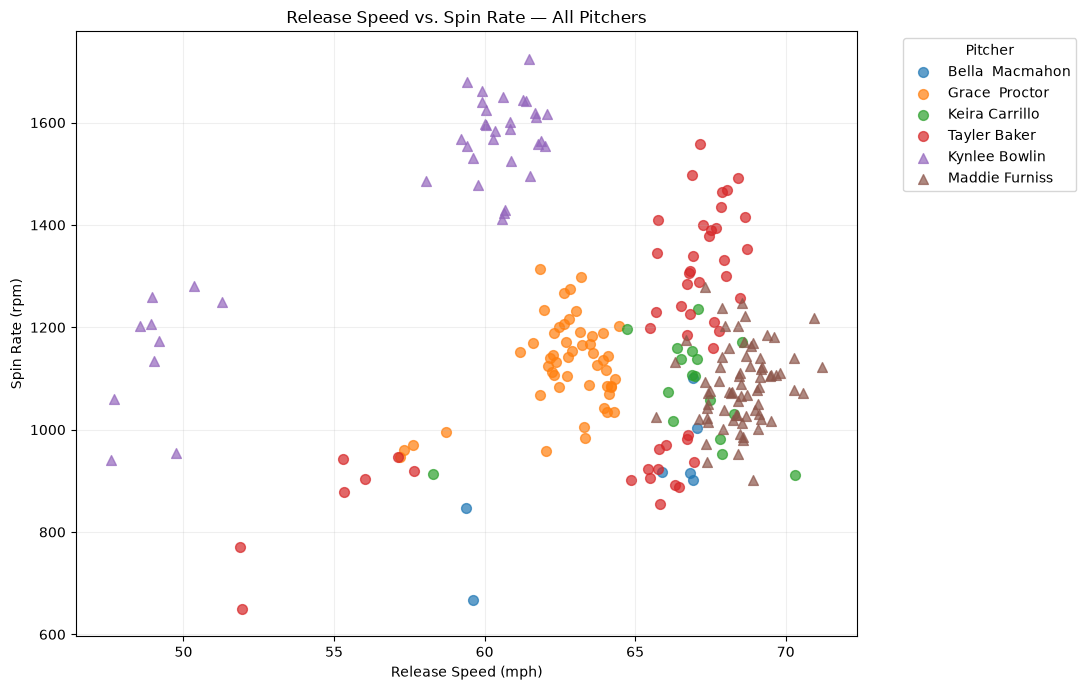

Team markers: {'South dakota state [sou03:2025]': 'o', 'Uta fall 25': '^'}


In [50]:

# Cell 11: Visualize release speed versus spin rate

import matplotlib.pyplot as plt

# Select pitches with both required measurements
plot_df = pitch_df.dropna(
    subset=["RelSpeed", "SpinRate"]
).copy()

print(f"Pitches available for visualization: {len(plot_df)}")

# Assign marker shapes to distinguish teams
teams = sorted(plot_df["PitcherTeam"].unique())

team_markers = dict(zip(teams, ["o", "^"]))

# Create the figure and coordinate system
fig, ax = plt.subplots(figsize=(11, 7))

# Plot each pitcher's observations separately
for (team, pitcher), group in plot_df.groupby(
    ["PitcherTeam", "Pitcher"]
):
    ax.scatter(
        group["RelSpeed"],
        group["SpinRate"],
        label=pitcher,
        marker=team_markers[team],
        alpha=0.7,
        s=50
    )

# Label axes and figure
ax.set_xlabel("Release Speed (mph)")
ax.set_ylabel("Spin Rate (rpm)")
ax.set_title("Release Speed vs. Spin Rate — All Pitchers")

# Add legend and grid
ax.legend(
    title="Pitcher",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# Show which marker represents each team
print("Team markers:", team_markers)


#### We are now going to bridge from this notebook towards nate's. Ideally adding some statistical inference

### Do pitch types differ in release velocity?

#### Null: The velocity distributions are identical across pitch types
#### Alt: At least one pitch type has a different velocity distribution
#### Begin with Krustal-Wallis test because it doesn't require normally distributed observations. It will compare their rank instead of raw numerical values. However, it still assumes independent observations.

In [51]:

# Cell 12: Compare release velocity across verified pitch types

from scipy.stats import kruskal

# Use only pitches with original UTA pitch-type labels
stat_df = df.loc[
    df["PitcherTeam"] == "Uta fall 25",
    ["Pitcher", "TaggedPitchType", "RelSpeed"]
].copy()

# Correct the known spelling inconsistency
stat_df["PitchType"] = (
    stat_df["TaggedPitchType"]
    .str.strip()
    .replace({"RIse": "Rise"})
)

# Keep observations with both pitch type and velocity
stat_df = stat_df.dropna(
    subset=["PitchType", "RelSpeed"]
)

# Summarize velocity by pitch type
velocity_summary = (
    stat_df.groupby("PitchType")["RelSpeed"]
    .agg(
        N="count",
        Mean="mean",
        Median="median",
        SD="std"
    )
    .round(2)
)

display(velocity_summary)

# Select groups with at least 5 observed velocities
eligible_types = velocity_summary.index[
    velocity_summary["N"] >= 5
]

# Collect velocity observations for each group
samples = [
    stat_df.loc[
        stat_df["PitchType"] == pitch_type,
        "RelSpeed"
    ].to_numpy()
    for pitch_type in eligible_types
]

# Perform exploratory Kruskal-Wallis test
H, p_value = kruskal(*samples)

print("Pitch types tested:", list(eligible_types))
print(f"Kruskal-Wallis H: {H:.4f}")
print(f"P-value: {p_value:.6g}")


,N,Mean,Median,SD
PitchType,,,,
Change,10,49.13,48.99,1.12
Curve,40,68.02,68.33,1.84
Fast,2,60.18,60.18,0.25
Rise,29,67.40,68.54,3.15
Screw,33,62.89,61.29,3.85


Pitch types tested: ['Change', 'Curve', 'Rise', 'Screw']
Kruskal-Wallis H: 46.1170
P-value: 5.35578e-10


#### Our Kruskal-Wallis examines differences in the ranks of observations across groups. With p = 5.35578e-10 < 0.05 we can reject our null hypothesis and suggest that our observed data provides evidence that release velocity distributions differ among the four tested UTA pitch types. This test was done only on UTA because UTA is the only team with the TaggedPitchType. Although were only running tests on UTA's data for now later we will look towards an imputing sytem for south dakota's data that assigns type based on grouping we give it

### Compare release velocity across all six pitchers

#### We will again use Kruskal-Wallis but this time our grouping variable is Pitcher. Our null is that all distributions for release velocities are equal while are alt is that at least one pitchers distribution differs

In [52]:

# Cell 13: Kruskal-Wallis test across all six pitchers

from scipy.stats import kruskal

# Create a separate dataset containing valid release speeds
velocity_df = pitch_df.dropna(
    subset=["Pitcher", "RelSpeed"]
).copy()

# Summarize release velocity for each pitcher
velocity_by_pitcher = (
    velocity_df.groupby("Pitcher")["RelSpeed"]
    .agg(
        N="count",
        Mean="mean",
        Median="median",
        SD="std"
    )
    .sort_values("Median")
    .round(2)
)

print("Release velocity by pitcher:")
display(velocity_by_pitcher)

# Create one array of velocities for each pitcher
velocity_groups = [
    group["RelSpeed"].to_numpy()
    for pitcher, group in velocity_df.groupby("Pitcher")
]

# Perform exploratory Kruskal-Wallis test
H, p = kruskal(*velocity_groups)

print(f"\nTotal pitches: {len(velocity_df)}")
print(f"Number of pitchers: {len(velocity_groups)}")
print(f"Kruskal-Wallis H: {H:.4f}")
print(f"P-value: {p:.6g}")


Release velocity by pitcher:


,N,Mean,Median,SD
Pitcher,,,,
Kynlee Bowlin,42,57.85,60.11,5.03
Grace Proctor,51,62.65,62.83,1.68
Tayler Baker,49,65.22,66.75,4.37
Bella Macmahon,7,64.66,66.82,3.55
Keira Carrillo,17,66.67,66.99,2.48
Maddie Furniss,73,68.51,68.53,1.00



Total pitches: 239
Number of pitchers: 6
Kruskal-Wallis H: 176.5298
P-value: 2.94743e-36


#### For our Kruskal-Wallis tests, the independence assumption is questionable. Each of our six groups represents repeated measurements from one pitcher, not independent athlets randompy sampled from a population. Because of this we can calculate the statistic to characterize separation in this dataset, but its conventional p-val should not be used to claim that pitchers generally differ across games or seasons

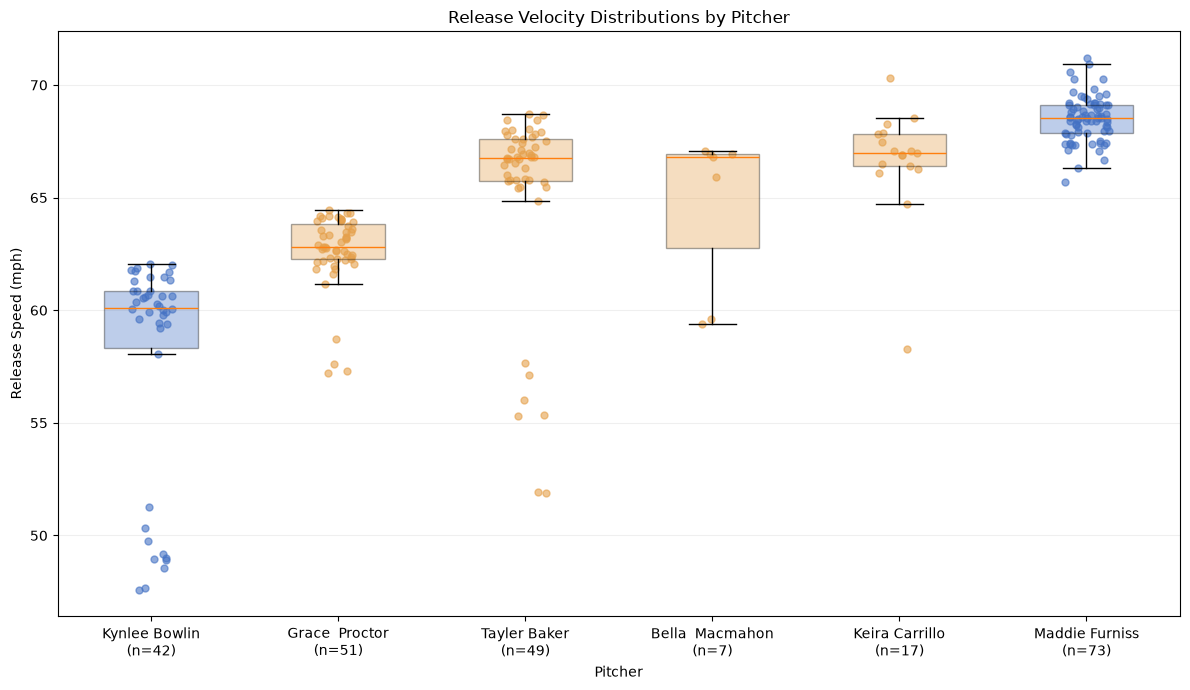

In [53]:

# Cell 14: Velocity distribution by pitcher

import numpy as np
import matplotlib.pyplot as plt

# Order pitchers by median velocity
pitcher_order = velocity_by_pitcher.index.tolist()

# Collect velocity measurements for each pitcher
velocity_groups = [
    velocity_df.loc[
        velocity_df["Pitcher"] == pitcher,
        "RelSpeed"
    ].to_numpy()
    for pitcher in pitcher_order
]

# Identify each pitcher's team
pitcher_teams = (
    velocity_df.drop_duplicates(subset="Pitcher")
    .set_index("Pitcher")["PitcherTeam"]
)

# Create plot
fig, ax = plt.subplots(figsize=(12, 7))

bp = ax.boxplot(
    velocity_groups,
    positions=range(1, len(pitcher_order) + 1),
    patch_artist=True,
    showfliers=False,
    widths=0.5
)

# Color boxes according to team
team_colors = {
    "Uta fall 25": "#4472C4",
    "South dakota state [sou03:2025]": "#E5A04B"
}

rng = np.random.default_rng(42)

for i, pitcher in enumerate(pitcher_order):

    team = pitcher_teams.loc[pitcher]
    color = team_colors[team]

    # Color corresponding box
    bp["boxes"][i].set_facecolor(color)
    bp["boxes"][i].set_alpha(0.35)

    # Overlay actual recorded pitches
    velocities = velocity_groups[i]

    jitter = rng.uniform(
        -0.12, 0.12, size=len(velocities)
    )

    ax.scatter(
        np.full(len(velocities), i + 1) + jitter,
        velocities,
        color=color,
        alpha=0.6,
        s=25
    )

# Include sample sizes in axis labels
labels = [
    f"{pitcher}\n(n={len(velocity_groups[i])})"
    for i, pitcher in enumerate(pitcher_order)
]

ax.set_xticks(
    range(1, len(pitcher_order) + 1),
    labels
)

ax.set_ylabel("Release Speed (mph)")
ax.set_xlabel("Pitcher")
ax.set_title("Release Velocity Distributions by Pitcher")

ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()
